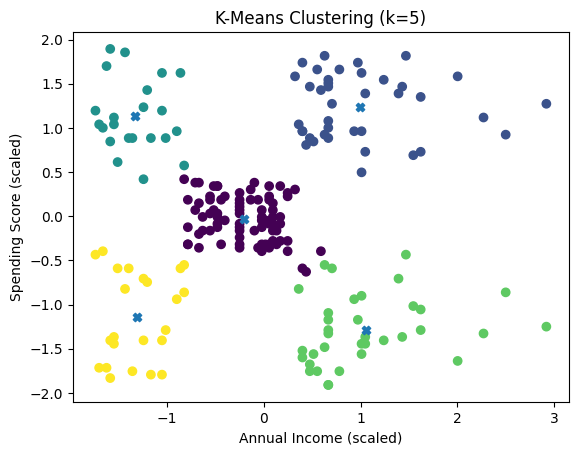

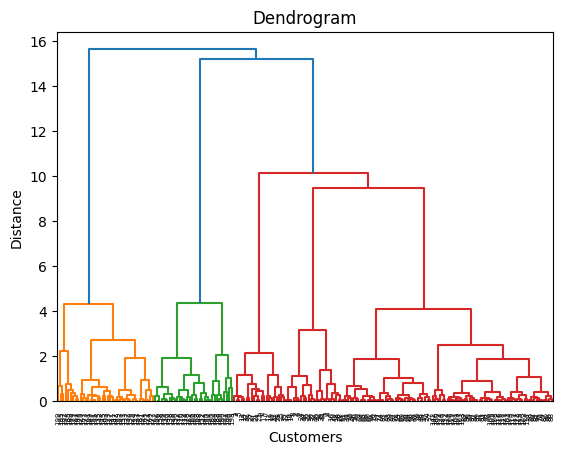

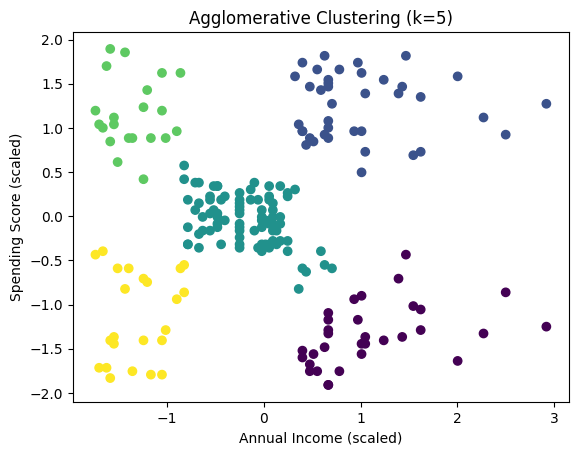

In [11]:
# Mall Customer Segmentation (Clustering)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

''' •	(5 marks) Load the dataset, drop CustomerID,
and select Annual Income (k$)
and Spending Score (1-100) as features.
Standardize these features and
justify why scaling matters before K-Means.

'''

# Load the dataset
df = pd.read_csv("/content/Mall_Customers.csv")

# drop CustomerID
df = df.drop(columns=["CustomerID"])
# print(df)


# Spending Score (1-100) as features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
# print(X)


# Standardize these features
scaler = StandardScaler()
# scaling matters
X_scaled = scaler.fit_transform(X)



'''
•	(8 marks) Fit K-Means with k = 5 clusters on the standardized data.
Create a scatter plot of the resulting clusters (color-coded),
with the centroids clearly marked.
'''

# K-Means with k = 5 clusters on the standardized data
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

centroids = kmeans.cluster_centers_

# plot
plt.figure()
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels)
plt.scatter(centroids[:, 0], centroids[:, 1], marker='X')
plt.title("K-Means Clustering (k=5)")
plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.show()


# # 4. Hierarchical Clustering
agg = AgglomerativeClustering(n_clusters=5)
agg_labels = agg.fit_predict(X_scaled)


# # Dendrogram
# plot
linked = linkage(X_scaled, method='ward')
plt.figure()
dendrogram(linked)
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()


# Plot Agglomerative clusters
# plot
plt.figure()
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=agg_labels)
plt.title("Agglomerative Clustering (k=5)")
plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.show()

In [9]:
!pip install ucimlrepo

In [10]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
optical_recognition_of_handwritten_digits = fetch_ucirepo(id=80)

# data (as pandas dataframes)
X = optical_recognition_of_handwritten_digits.data.features
y = optical_recognition_of_handwritten_digits.data.targets

# metadata
print(optical_recognition_of_handwritten_digits.metadata)

# variable information
print(optical_recognition_of_handwritten_digits.variables)


{'uci_id': 80, 'name': 'Optical Recognition of Handwritten Digits', 'repository_url': 'https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits', 'data_url': 'https://archive.ics.uci.edu/static/public/80/data.csv', 'abstract': 'Two versions of this database available; see folder', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 5620, 'num_features': 64, 'feature_types': ['Integer'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1998, 'last_updated': 'Wed Aug 23 2023', 'dataset_doi': '10.24432/C50P49', 'creators': ['E. Alpaydin', 'C. Kaynak'], 'intro_paper': {'ID': 280, 'type': 'NATIVE', 'title': 'Methods of Combining Multiple Classifiers and Their Applications to Handwritten Digit Recognition', 'authors': 'C. Kaynak', 'venue': 'MSc Thesis, Institute of Graduate Studies in Science and Engineering, 

Dataset Shape: (569, 31)

Missing Values:
 radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
target                0
dtype: int64

Class Distribution:
 0    357
1    212
Name: count, dtype: int64

Class Distribution (%):
 0    62.741652
1    37.258348
Name: proportion, dtype: float64

Model Comparison:

                     Accu

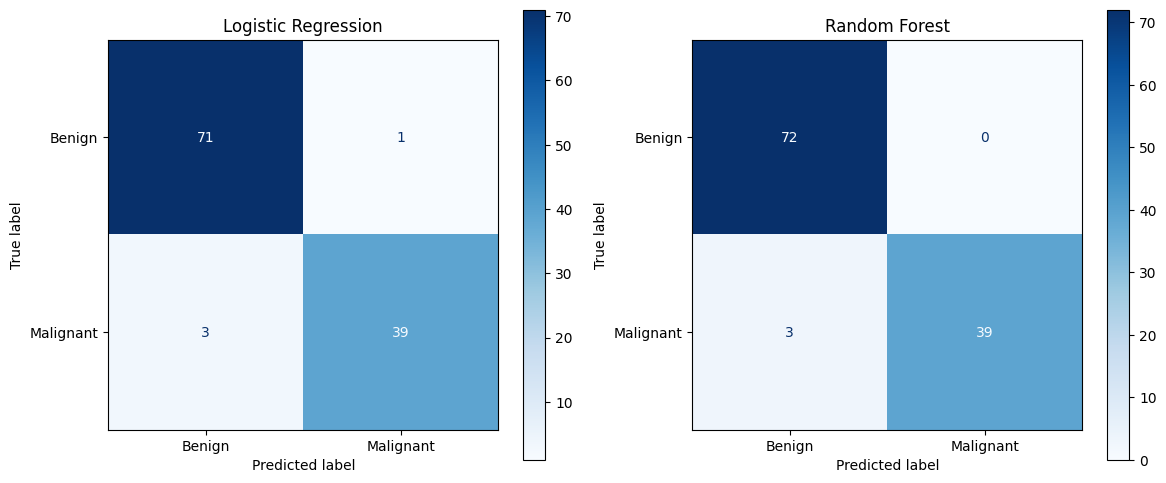

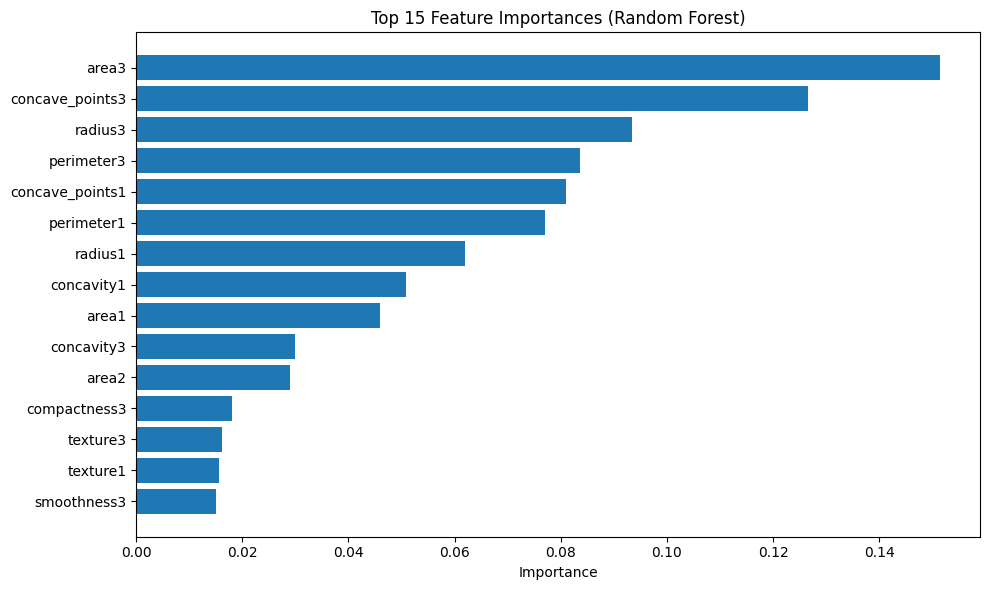


Top 5 Important Features:

            Feature  Importance
23            area3    0.151412
27  concave_points3    0.126497
20          radius3    0.093475
22       perimeter3    0.083642
7   concave_points1    0.081082


In [18]:
# Breast Cancer Classification (Supervised Learning)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)


data = fetch_ucirepo(id=17)

X = data.data.features
y = data.data.targets


y = y.values.ravel()
y = np.where(y == 'M', 1, 0)

df = X.copy()
df['target'] = y

print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:\n", df.isnull().sum())


print("\nClass Distribution:\n", pd.Series(y).value_counts())
print("\nClass Distribution (%):\n", pd.Series(y).value_counts(normalize=True) * 100)



X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



lr = LogisticRegression(max_iter=5000, random_state=42)
lr.fit(X_train_scaled, y_train)


rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)




def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

results = []
results.append(evaluate_model(lr, X_test_scaled, y_test, "Logistic Regression"))
results.append(evaluate_model(rf, X_test, y_test, "Random Forest"))

results_df = pd.DataFrame(results).set_index("Model").round(4)
print("\nModel Comparison:\n")
print(results_df)




fig, axes = plt.subplots(1, 2, figsize=(12, 5))


ConfusionMatrixDisplay.from_estimator(
    lr, X_test_scaled, y_test,
    display_labels=["Benign", "Malignant"],
    cmap="Blues", ax=axes[0]
)
axes[0].set_title("Logistic Regression")


ConfusionMatrixDisplay.from_estimator(
    rf, X_test, y_test,
    display_labels=["Benign", "Malignant"],
    cmap="Blues", ax=axes[1]
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()



importances = rf.feature_importances_
feature_names = X.columns

feat_imp = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)


plt.figure(figsize=(10, 6))
plt.barh(feat_imp["Feature"].head(15), feat_imp["Importance"].head(15))
plt.title("Top 15 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


print("\nTop 5 Important Features:\n")
print(feat_imp.head(5))


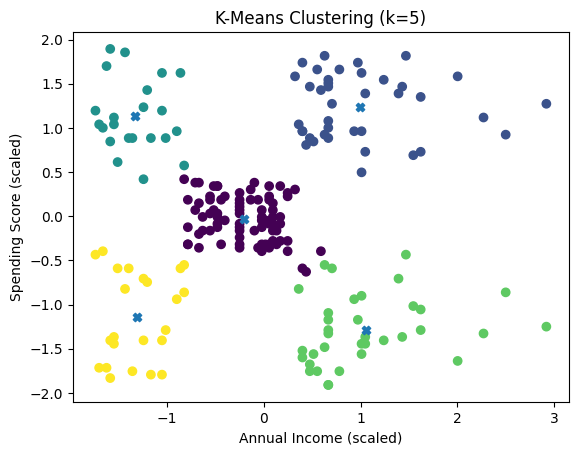

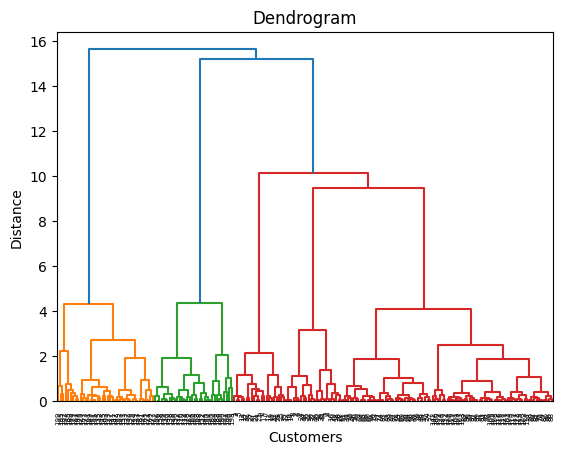

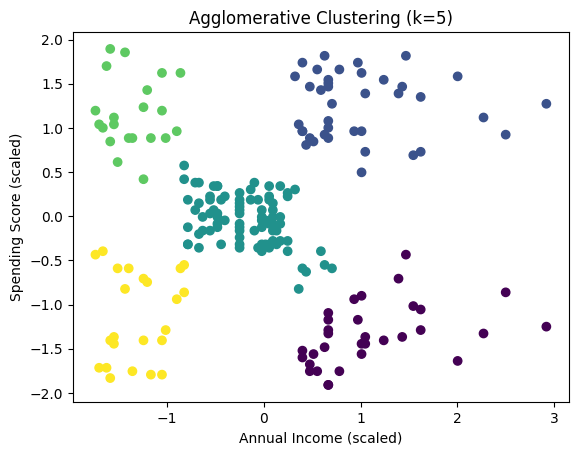

In [14]:
# Mall Customer Segmentation (Clustering)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

df = pd.read_csv("/content/Mall_Customers.csv")

# drop
df = df.drop(columns=["CustomerID"])
# print(df)


X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
# print(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=5, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

centroids = kmeans.cluster_centers_

# plot
plt.figure()
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels)
plt.scatter(centroids[:, 0], centroids[:, 1], marker='X')
plt.title("K-Means Clustering (k=5)")
plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.show()

agg = AgglomerativeClustering(n_clusters=5)
agg_labels = agg.fit_predict(X_scaled)

# plot
linked = linkage(X_scaled, method='ward')
plt.figure()
dendrogram(linked)
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()

# plot
plt.figure()
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=agg_labels)
plt.title("Agglomerative Clustering (k=5)")
plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.show()